# Task 3: Lightweight IoT IDS benchmark
**Ilkhan Kuanyshev | Research Results, Data Analysis and Scientific Visualization**

This notebook analyses **measured local execution times on synthetic smoke input**.
The input is the upstream ten-row schema fixture with jittered resampling, not the
real CICIoT2023 dataset. All quality scores are demonstration outputs. H1.1-H1.3
remain **not tested**. This notebook does not train or fabricate timing data.

Run Kernel > Restart & Run All. Processing and plotting functions live in `src/`.
The saved outputs permit inspection without a rerun.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/process_data.py').exists()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src.process_data import process
from src.visualize import figures
SEED = 42
np.random.seed(SEED)
meta = json.loads(Path('data/raw/provenance.json').read_text())
assert hashlib.sha256(Path('data/raw/test_run.jsonl').read_bytes()).hexdigest() == meta['raw_sha256']
display({k: meta[k] for k in ['data_origin','timing_origin','hardware_scope','hypotheses']})

{'data_origin': 'synthetic_smoke',
 'timing_origin': 'measured',
 'hardware_scope': 'local Windows host, unconstrained; NOT Raspberry Pi or 1-vCPU Docker',
 'hypotheses': 'NOT TESTED - synthetic smoke data'}

## 1. Ingestion, validation and warm-up filtering
The parser rejects malformed records, non-finite/negative durations, duplicate identities
and mixed real/synthetic provenance. Warm-up is excluded by phase, not by latency.
Runtime errors remain in the denominator. IQR flags are per configuration and process;
they identify unusual values, not their physical cause, and no flagged row is removed.

In [2]:
raw, benchmark, runs, summary, audit = process(seed=SEED, resamples=4000)
display(pd.DataFrame([audit]).T.rename(columns={0:'value'}))
assert len(raw) == audit['warmup_rows'] + len(benchmark)
display(raw[['model','n_features','precision','phase','status','latency_ms']].head())

,value
raw_rows,30800
warmup_rows,2800
benchmark_attempts,28000
benchmark_errors,0
iqr_flagged_not_removed,3380
seed,42
bootstrap_resamples,4000
origin,[synthetic_smoke]
warning,CI is descriptive: folds overlap and few proce...


,model,n_features,precision,phase,status,latency_ms
0,cnn1d,15,fp32,warmup,ok,0.3696
1,cnn1d,15,fp32,warmup,ok,0.0445
2,cnn1d,15,fp32,warmup,ok,0.0704
3,cnn1d,15,fp32,warmup,ok,0.0261
4,cnn1d,15,fp32,warmup,ok,0.0241


## 2. Aggregation and uncertainty
For each fresh process/split, calculate mean, sample SD, p25/p50/p75/p95/p99.
Bootstrap whole unit metrics (4,000 resamples, seed 42), then estimate the mean
unit percentile. Do not treat 1,000 repeated calls as 1,000 independent replications.
Only two overlapping CV splits are available: CIs are descriptive and may be unstable.
The SD in the summary table is across unit metrics; `run_summary.csv` also stores
within-process request SD. No inferential hypothesis decision is justified.

In [3]:
display(summary[['model','n_features','precision','n_units','p50_ms','p50_ms_sd','p95_ms','p99_ms','p50_ms_ci_low','p50_ms_ci_high','error_rate']].round(6))
print('Outputs: metrics_summary.csv, run_summary.csv, request_flags.csv and audit.json')

,model,n_features,precision,n_units,p50_ms,p50_ms_sd,p95_ms,p99_ms,p50_ms_ci_low,p50_ms_ci_high,error_rate
0,cnn1d,15,fp32,2,0.02425,0.000071,0.028555,0.039424,0.0242,0.0243,0.0
1,cnn1d,15,int8,2,0.03330,0.000141,0.041365,0.073814,0.0332,0.0334,0.0
2,cnn1d,46,fp32,2,0.02625,0.000071,0.037705,0.053972,0.0262,0.0263,0.0
3,cnn1d,46,int8,2,0.03475,0.000212,0.051025,0.074515,0.0346,0.0349,0.0
4,decision_tree,15,fp32,2,0.01270,0.000000,0.019382,0.027211,0.0127,0.0127,0.0
5,decision_tree,46,fp32,2,0.01280,0.000000,0.017205,0.026751,0.0128,0.0128,0.0
6,lightgbm,15,fp32,2,0.02405,0.000495,0.029300,0.040704,0.0237,0.0244,0.0
7,lightgbm,46,fp32,2,0.02405,0.000071,0.028552,0.047969,0.0240,0.0241,0.0
8,mlp,15,fp32,2,0.02665,0.000071,0.043055,0.061203,0.0266,0.0267,0.0
9,mlp,15,int8,2,0.03340,0.000141,0.038902,0.061057,0.0333,0.0335,0.0


Outputs: metrics_summary.csv, run_summary.csv, request_flags.csv and audit.json


## 3. Failures, throughput and demonstration quality
Quality is calculated from the exported ONNX graph. The table is not a valid estimate
of real attack detection. Throughput is measured separately at batch=256; it is not
an arrival rate or the reciprocal of p50. Configuration failures, including workers
that emitted no log, are checked separately. Zero observed errors is not proof of
zero future failure probability.

In [4]:
quality = pd.read_csv('data/processed/quality_metrics.csv')
failed = quality[quality.status != 'ok']
display({'configuration_failures': len(failed), 'configuration_rows': len(quality),
         'timed_call_errors': audit['benchmark_errors']})
display(quality[quality.model != 'dummy'].groupby(['model','n_features','precision'])[
    ['macro_f1','benign_fpr','throughput_rps','model_size_kb','ram_peak_mb']].mean().round(5))
display(Markdown('**Synthetic-input quality only. No scientific or deployment winner is selected.**'))
qs = pd.read_csv('data/processed/quality_summary.csv')
display(qs[['model','n_features','precision','throughput_rps_mean','throughput_rps_sd','throughput_rps_p50','throughput_rps_p95','throughput_rps_p99','throughput_rps_ci_low','throughput_rps_ci_high']].round(3))

{'configuration_failures': 0, 'configuration_rows': 30, 'timed_call_errors': 0}

macro_f1  benign_fpr  throughput_rps  \
model         n_features precision                                         
cnn1d         15         fp32        0.44792       1.000    1.463203e+06   
                         int8        0.44679       1.000    8.073704e+05   
              46         fp32        0.81710       0.425    9.542922e+05   
                         int8        0.81719       0.425    3.063110e+05   
decision_tree 15         fp32        1.00000       0.000    5.646473e+06   
              46         fp32        1.00000       0.000    5.700312e+06   
lightgbm      15         fp32        0.99373       0.050    1.285826e+05   
              46         fp32        0.99375       0.000    1.294727e+05   
mlp           15         fp32        0.61707       0.425    2.403698e+06   
                         int8        0.61707       0.425    1.957545e+06   
              46         fp32        0.79530       0.025    1.738729e+06   
                         int8        0.79243       0.025    1.113513e+06   
random_forest 15         fp32        1.00000       0.000    1.999717e+05   
              46         fp32        1.00000       0.000    2.054210e+05   

                                    model_size_kb  ram_peak_mb  
model         n_features precision                              
cnn1d         15         fp32            32.20117     55.74805  
                         int8            12.04199     56.03906  
              46         fp32            94.44727     56.41211  
                         int8            27.78955     57.32422  
decision_tree 15         fp32             1.74414     55.05273  
              46         fp32             1.74414     55.22656  
lightgbm      15         fp32           161.35449     56.09180  
              46         fp32           160.57031     56.29102  
mlp           15         fp32            14.64258     55.53320  
                         int8             8.58105     55.70898  
              46         fp32            22.69824     55.49805  
                         int8            10.82227     55.89258  
random_forest 15         fp32           136.45605     55.75195  
              46         fp32           133.89258     55.87305

**Synthetic-input quality only. No scientific or deployment winner is selected.**

,model,n_features,precision,throughput_rps_mean,throughput_rps_sd,throughput_rps_p50,throughput_rps_p95,throughput_rps_p99,throughput_rps_ci_low,throughput_rps_ci_high
0,cnn1d,15,fp32,1463203.313,68405.036,1463203.313,1506736.012,1510605.585,1414833.649,1511572.978
1,cnn1d,15,int8,807370.448,6805.611,807370.448,811701.512,812086.496,802558.154,812182.742
2,cnn1d,46,fp32,954292.188,39357.725,954292.188,979339.291,981565.700,926462.074,982122.303
3,cnn1d,46,int8,306310.960,60199.466,306310.960,344621.665,348027.061,263743.509,348878.410
4,decision_tree,15,fp32,5646473.297,242832.591,5646473.297,5801011.012,5814747.698,5474764.726,5818181.869
5,decision_tree,46,fp32,5700312.361,16155.221,5700312.361,5710593.481,5711507.358,5688888.895,5711735.827
6,lightgbm,15,fp32,128582.593,25189.790,128582.593,144613.277,146038.227,110770.722,146394.464
7,lightgbm,46,fp32,129472.666,14448.349,129472.666,138667.539,139484.861,119256.140,139689.192
8,mlp,15,fp32,2403698.278,54565.634,2403698.278,2438423.635,2441510.333,2365114.548,2442282.008
9,mlp,15,int8,1957545.191,15241.166,1957545.191,1967244.609,1968106.780,1946768.059,1968322.323


## 4. Visualization and export
Figure 1 varies selected feature count, the actual workload factor in this experiment.
The rubric filename is retained, but the axis is not labelled RPS: no offered-load
experiment was performed. The shaded bands show the unit bootstrap intervals.
Figure 2 compares unit p50 distributions at 46 features/FP32; it includes both unit
points and bootstrap error caps. PNG exports are 300 DPI; PDF exports are vector.

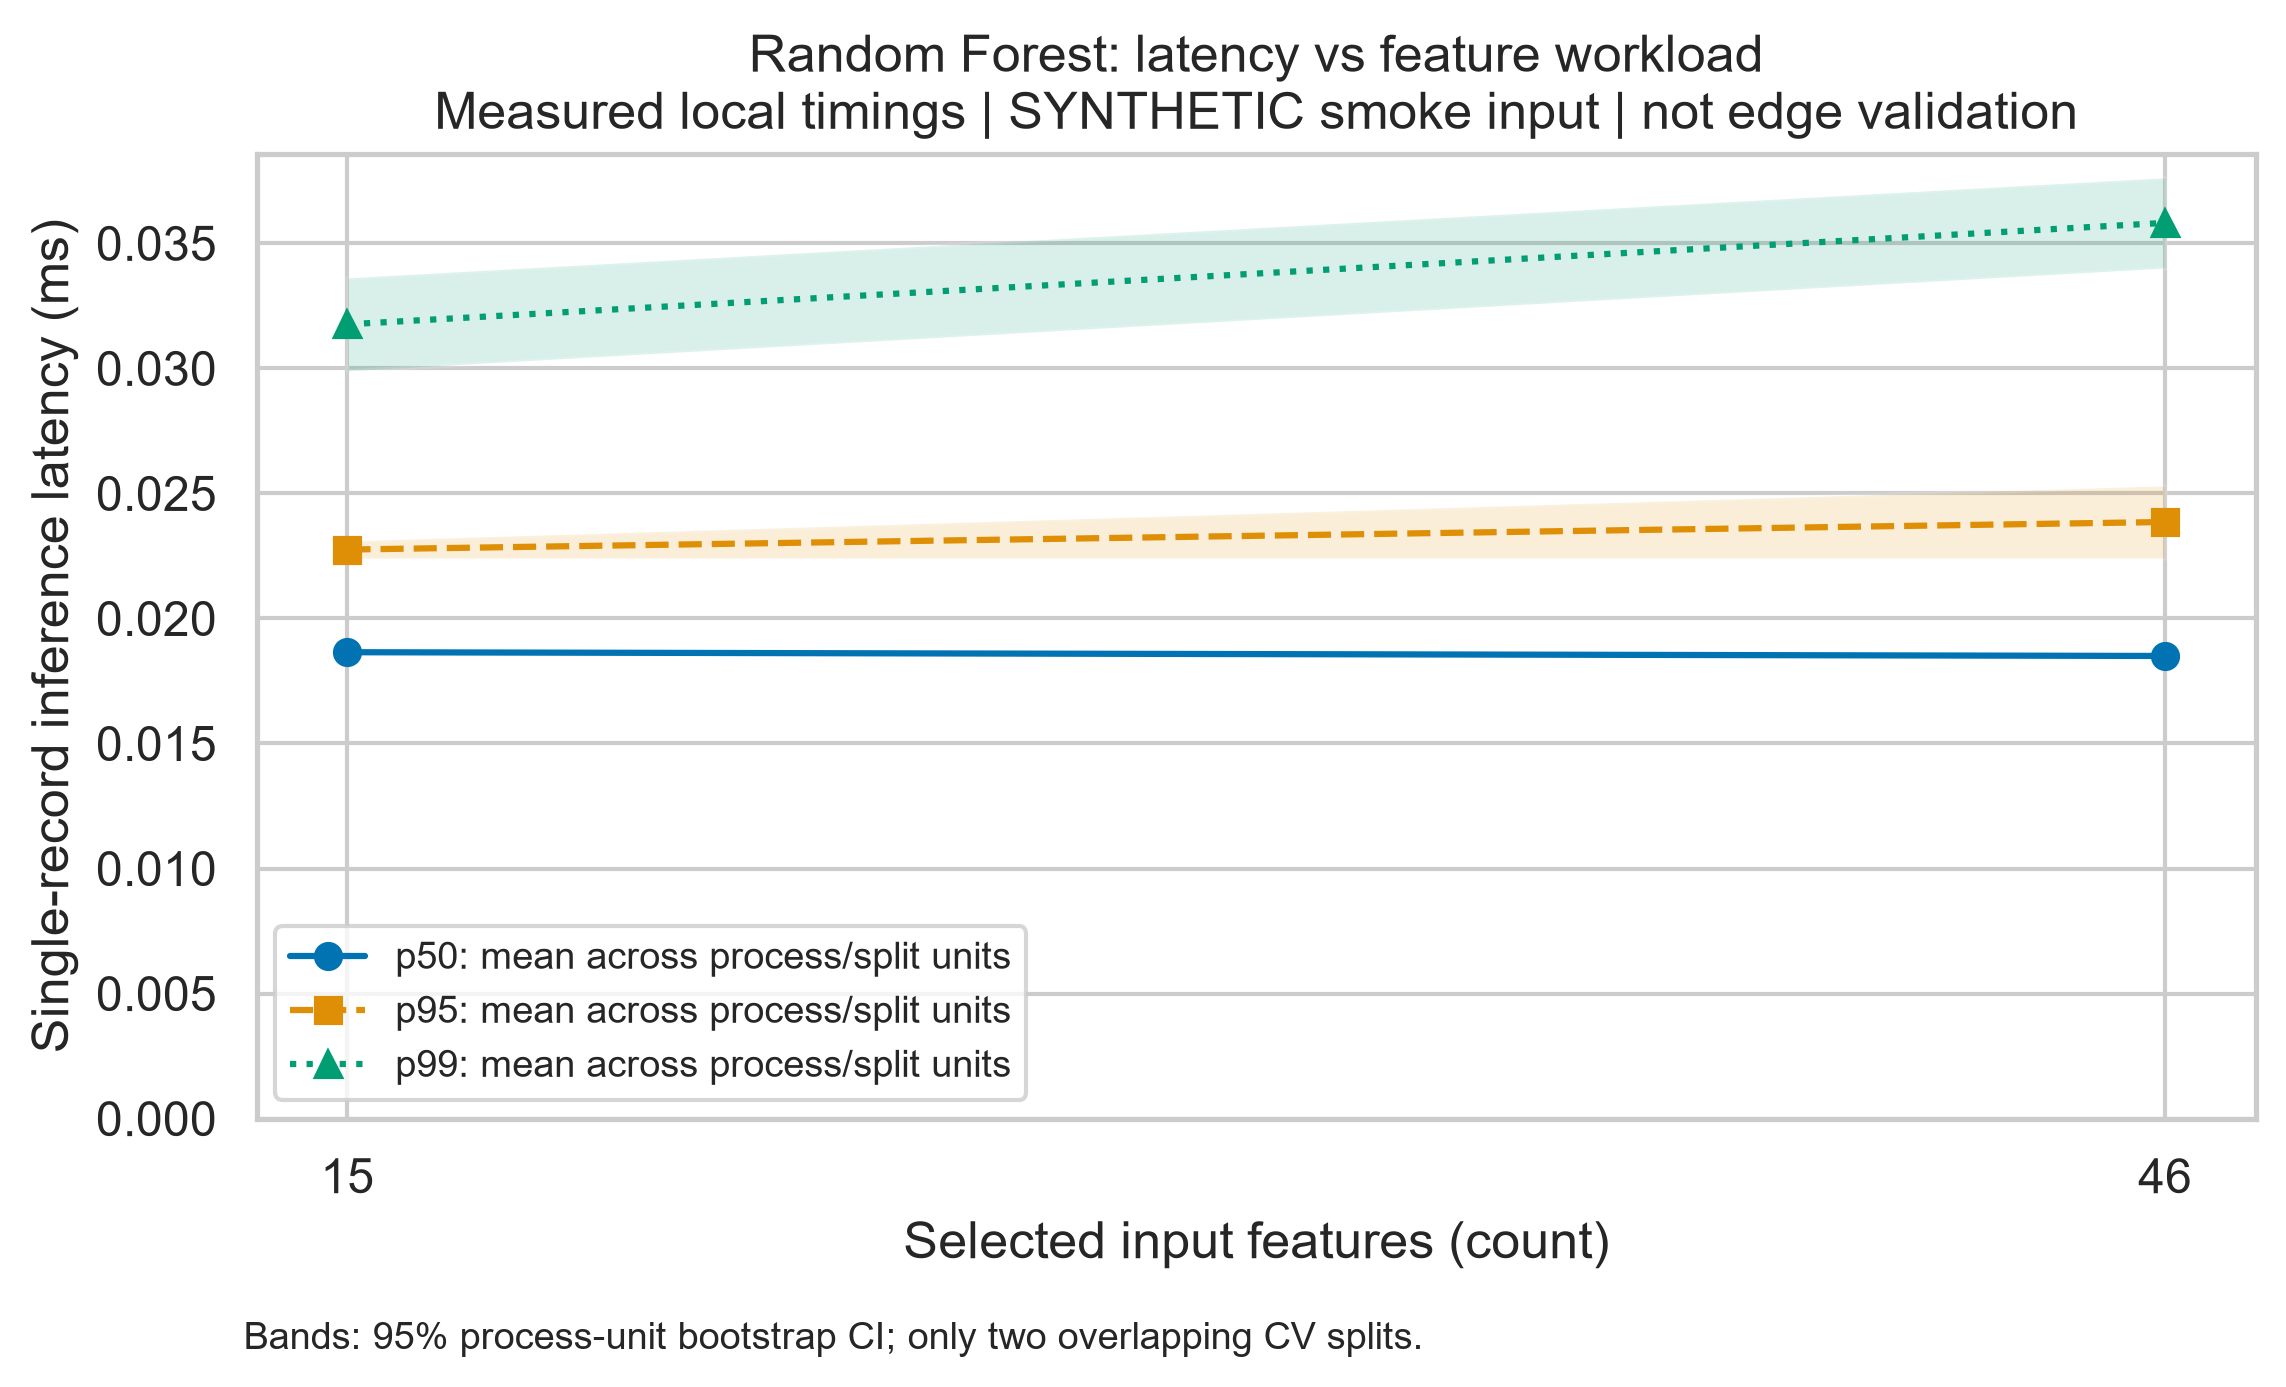

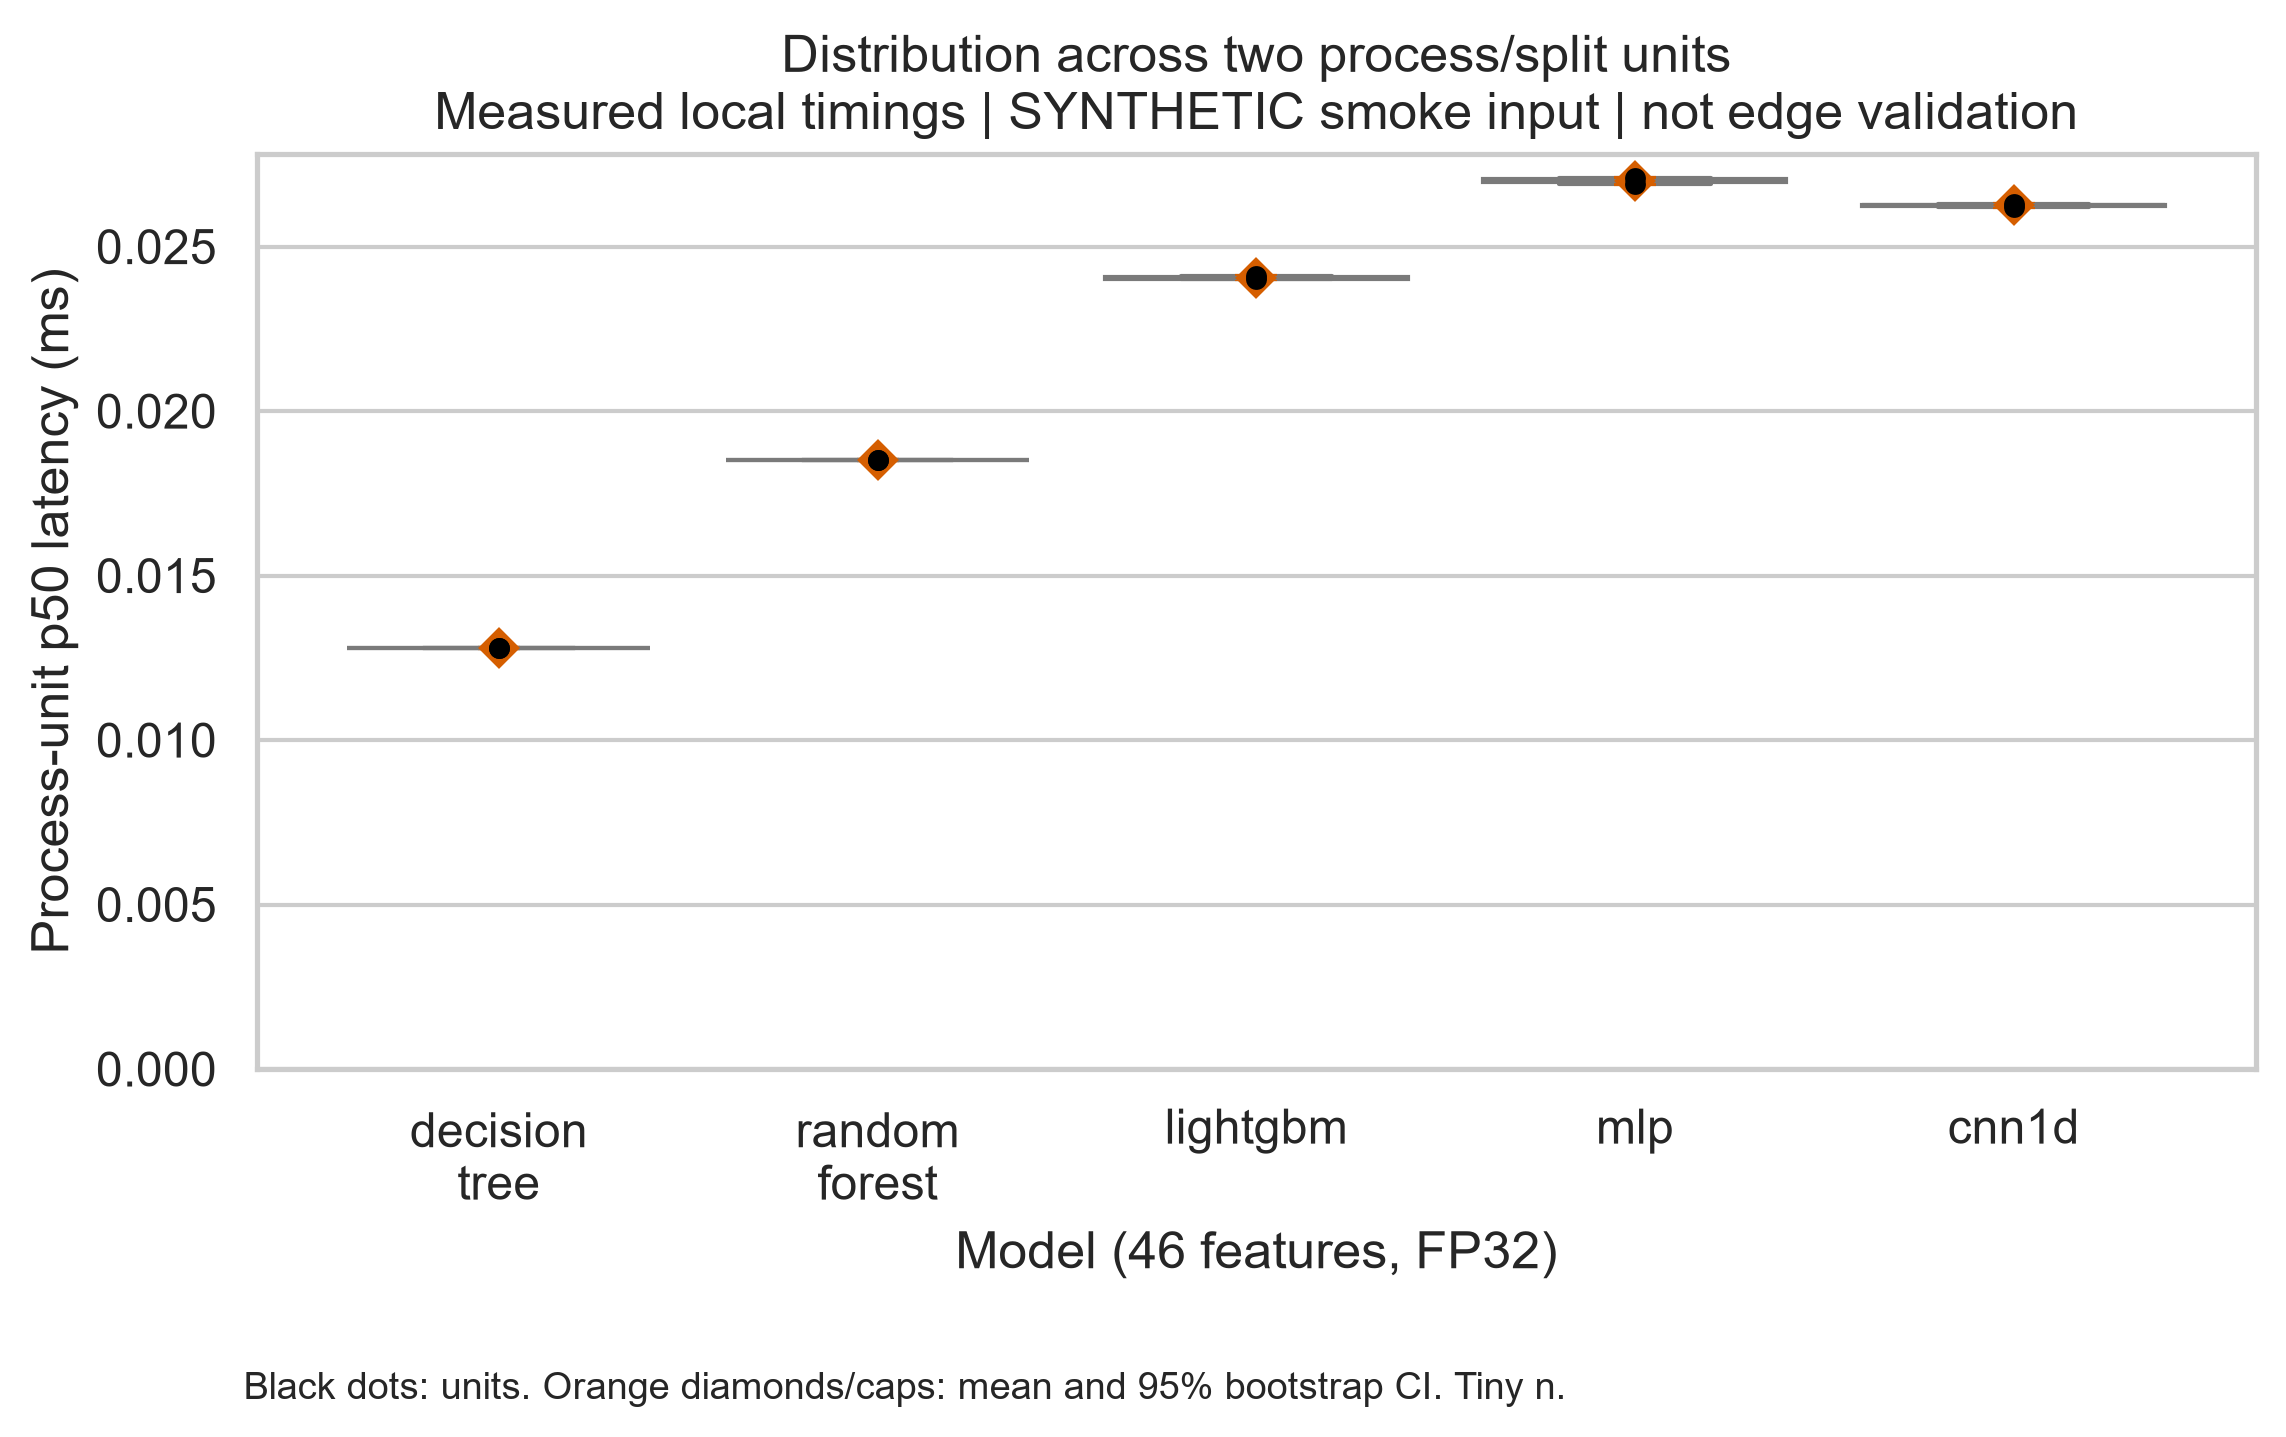

Saved both PNG and PDF versions of each figure.


In [5]:
paths = figures(summary, runs)
for path in paths:
    display(Image(filename=str(path), width=850))
print('Saved both PNG and PDF versions of each figure.')

## 5. Formal model and interpretation
See [domain_model.md](../docs/domain_model.md) for cross entropy, macro-F1,
benign FPR, constrained optimisation, notation, measurement boundaries and STRIDE.

The full study compares five families at k = 46/30/15/10, with INT8 for MLP/CNN,
on the same 15 splits and target platform. This delivered run only checks the
processing path. Smaller feature count is a proposed method, not a demonstrated
improvement: runtime variation can be larger than its effect in this tiny fixture.
Repeated CV splits share data, so the Task 2 tests need an explicit dependence audit.
Real-data acquisition, target-device runs and public release remain outstanding.

In [6]:
display(Markdown('### Evidence status\n| Claim | Status |\n|---|---|\n| Code ran and timings collected | Measured local smoke run |\n| CICIoT2023 detection quality | Not measured on real data |\n| Raspberry Pi / constrained Docker | Not measured |\n| H1.1, H1.2, H1.3 | Not tested |\n| Deployment recommendation | Not supported |'))

### Evidence status
| Claim | Status |
|---|---|
| Code ran and timings collected | Measured local smoke run |
| CICIoT2023 detection quality | Not measured on real data |
| Raspberry Pi / constrained Docker | Not measured |
| H1.1, H1.2, H1.3 | Not tested |
| Deployment recommendation | Not supported |